# Exploratory Analysis of the Kaggle Payment Data

Four questions:

1. How imbalanced is the data, and in which transactions does fraud occur?
2. Which characteristics of a transaction distinguish fraudulent from legitimate payments?
3. Which columns cannot be used for modelling?
4. How does the data change over time, and how should it be split?

Merged data (after synthetic generation): `eda_merged.ipynb`. Figures: `reports/figures/eda/kaggle/`.

**Scope.** The analyses used to propose features (fraud rates by type, amount, hour and recipient history, single-feature AUC, correlations and the night window) use only steps 1 to 281, the earliest 60% of transactions, which lies inside the training set under both split options considered. The data quality checks, the dataset description and the comparison of split options use the full data, including fraud counts over time. Unless stated otherwise, figures refer to TRANSFER and CASH_OUT transactions within steps 1 to 281. All numbers are exploratory statistics, not estimates of model performance.

## Key findings

| Finding | Evidence | Implication |
|---|---|---|
| Fraud is rare and occurs in two transaction types only | Full data: 8,213 frauds out of 6,362,620 transactions (0.129%), all in TRANSFER and CASH_OUT. Within steps 1 to 281 the fraud rate is 0.50% for TRANSFER and 0.12% for CASH_OUT | Imbalance handling is required (about 523 legitimate transactions per fraud within the two types); PAYMENT, CASH_IN and DEBIT carry no fraud signal |
| The effect of amount depends on the transaction type | CASH_OUT fraud rate reaches 2.5% in the top amount decile, against 0.04% to 0.11% elsewhere; TRANSFER fraud rate is highest for the smallest amounts (1.2%) | Amount and type should be modelled jointly (tree-based models or an interaction term) |
| Fraud transaction value is concentrated in a minority of cases | Frauds of at least 1 million are 32.3% of cases but 86.0% of the fraud value | Cost-based evaluation will be dominated by large frauds; recall should be reported by count and by value |
| High night-time fraud rates reflect missing legitimate activity | Fraud count stays at 90 to 167 per hour while legitimate volume falls from 169,906 at 19:00 to 85 at 05:00; the fraud rate reaches 58.5% at 05:00 | Hour of day is informative, but the effect is partly a simulation artefact |
| Payments to first-time recipients are far riskier | Fraud rate 0.85% for first-time recipients against 0.05% to 0.12% otherwise | Recipient history features have the highest single-feature AUC among the usable candidates examined (up to 0.79) |
| Balance columns cannot be used, for different reasons | Post-transaction balances are not known at scoring time; pre-transaction balances follow simulator rules (97.9% of frauds transfer exactly the sender balance, against 0.0% of legitimate transactions) and are often implausible for legitimate transactions | All four are excluded from the main model; a comparison model may show how much performance depends on them |
| Legitimate activity collapses after day 17 (full data) | From step 400 onwards: 9.5% of transactions but 45.7% of frauds | Proposed: use the final period as the stream, so that the shift can be monitored; the split is not final |

## Setup

In [1]:
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.csv as pv
import pyarrow.parquet as pq
import pyarrow.compute as pc
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import matplotlib.transforms as mtransforms
from sklearn.metrics import roc_auc_score

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "requirements.txt").exists())  # repo root
RAW_DIR = ROOT / "data" / "raw"
CSV_NAME = "PS_20174392719_1491204439457_log.csv"
CSV_PATH = RAW_DIR / CSV_NAME
ZIP_PATH = RAW_DIR / "kaggle dataset.zip"
PARQUET_PATH = RAW_DIR / "paysim.parquet"
FIG_DIR = ROOT / "reports" / "figures" / "eda" / "kaggle"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Label analyses use steps 1 to TRAIN_END only: the earliest 60% of transactions,
# inside the training set under every split option. Update when the split is final.
TRAIN_END = 281

# Colours: legitimate = blue, fraud = orange, de-emphasised = grey
LEGIT, FRAUD, MUTED = "#2a78d6", "#eb6834", "#c3c2b7"
TRANSFER_C, CASH_OUT_C = "#1baf7a", "#2a78d6"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e6e5e1"

plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.edgecolor": GRID, "axes.linewidth": 0.8, "axes.labelcolor": INK2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": INK2, "ytick.color": INK2, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "font.size": 10, "axes.titlesize": 10, "axes.titlecolor": INK2, "axes.titlelocation": "left",
    "legend.frameon": False, "lines.linewidth": 2,
})
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

def headline(fig, text):
    # The figure title states the finding; panel titles describe the measure.
    # Called after tight_layout, it sits just above the panel titles.
    top = max(ax.get_position().y1 for ax in fig.axes)
    shift = mtransforms.offset_copy(fig.transFigure, fig=fig, x=0, y=22, units="points")
    fig.text(0.01, top, text, transform=shift, ha="left", va="bottom", fontsize=13, fontweight="bold", color=INK)

def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

pct = mtick.PercentFormatter(decimals=1)

## Data loading

The CSV is converted once to parquet. Only the columns needed for each step are loaded, which keeps memory use low.

In [2]:
COLUMN_TYPES = {
    "step": pa.int16(), "type": pa.string(), "amount": pa.float64(),
    "nameOrig": pa.string(), "oldbalanceOrg": pa.float64(), "newbalanceOrig": pa.float64(),
    "nameDest": pa.string(), "oldbalanceDest": pa.float64(), "newbalanceDest": pa.float64(),
    "isFraud": pa.int8(), "isFlaggedFraud": pa.int8(),
}

def csv_to_parquet(f):
    reader = pv.open_csv(f, convert_options=pv.ConvertOptions(column_types=COLUMN_TYPES))
    with pq.ParquetWriter(PARQUET_PATH, reader.schema, compression="zstd") as writer:
        for batch in reader:
            writer.write_batch(batch)

if not PARQUET_PATH.exists():
    if CSV_PATH.exists():
        csv_to_parquet(CSV_PATH)
    else:
        with zipfile.ZipFile(ZIP_PATH) as zf, zf.open(CSV_NAME) as f:
            csv_to_parquet(f)

NUM_COLS = ["step", "type", "amount", "oldbalanceOrg", "newbalanceOrig",
            "oldbalanceDest", "newbalanceDest", "isFraud", "isFlaggedFraud"]
df = pd.read_parquet(PARQUET_PATH, columns=NUM_COLS)
df["type"] = df["type"].astype("category")
df["hour"] = (df.step % 24).astype("int8")          # assumes step 0 corresponds to midnight
df["day"] = ((df.step - 1) // 24 + 1).astype("int8")
early = df.step <= TRAIN_END                         # mask for label analyses
print(f"{len(df):,} rows, {df.shape[1]} columns loaded; steps 1 to {TRAIN_END}: {early.sum():,} rows ({early.mean():.1%})")

6,362,620 rows, 11 columns loaded; steps 1 to 281: 3,820,599 rows (60.0%)


## Data quality (full data)

In [3]:
pf = pq.ParquetFile(PARQUET_PATH)
hashes = np.concatenate([pd.util.hash_pandas_object(b.to_pandas(), index=False).to_numpy()
                         for b in pf.iter_batches(batch_size=500_000)])
n_dup = len(hashes) - len(np.unique(hashes))
del hashes

quality = pd.DataFrame({
    "check": ["Rows", "Columns", "Missing values", "Exact duplicate rows", "Negative amounts",
              "Zero amounts (all fraud)", "Steps covered", "Transaction types"],
    "result": [f"{len(df):,}", "11", f"{int(df[NUM_COLS].isna().sum().sum()):,}", f"{n_dup:,}",
               f"{(df.amount < 0).sum():,}",
               f"{(df.amount == 0).sum():,} ({int(df.loc[df.amount == 0, 'isFraud'].sum())} fraud)",
               f"{df.step.min()} to {df.step.max()} ({df.step.nunique()} distinct)",
               ", ".join(sorted(df.type.cat.categories))],
})
quality

,check,result
0,Rows,"6,362,620"
1,Columns,11
2,Missing values,0
3,Exact duplicate rows,0
4,Negative amounts,0
5,Zero amounts (all fraud),16 (16 fraud)
6,Steps covered,1 to 743 (743 distinct)
7,Transaction types,"CASH_IN, CASH_OUT, DEBIT, PAYMENT, TRANSFER"


The raw data contains no missing values, duplicates or negative amounts. The only irregularity is a set of 16 transactions with an amount of zero, all labelled as fraud; their treatment is left to the cleaning step. Because the Kaggle data is already clean, the cleaning module will mainly concern the synthetic fields.

## Account identifiers and recipient history

Recipient history is computed from earlier transactions only. Rows are ordered by `step`, and by file order within the same step. History covers all transaction types and the full timeline; for transactions within steps 1 to 281 it therefore uses only data from that period.

In [4]:
tbl = pq.read_table(PARQUET_PATH, columns=["nameOrig", "nameDest"])
n_orig_unique = pc.count_distinct(tbl["nameOrig"]).as_py()
dest = tbl["nameDest"].combine_chunks()
dest_code = dest.dictionary_encode().indices.to_numpy()
df["dest_is_merchant"] = pc.starts_with(dest, "M").to_numpy(zero_copy_only=False)
n_dest_unique = int(dest_code.max()) + 1
del tbl, dest

# History features rely on row order: rows must be sorted by step (file order within a step).
assert df.step.is_monotonic_increasing, "rows are not ordered by step"
df["dest_prior_count"] = pd.Series(dest_code).groupby(dest_code).cumcount().to_numpy().astype("int32")
df["dest_steps_since_last"] = (df.step - df.step.groupby(dest_code).shift(1)).astype("float32")
df["is_new_dest"] = (df.dest_prior_count == 0).astype("int8")
del dest_code

print(f"Distinct senders (nameOrig):   {n_orig_unique:,} ({n_orig_unique / len(df):.2%} of rows)")
print(f"Distinct recipients (nameDest): {n_dest_unique:,}")
print(f"Frauds sent to merchants, steps 1 to {TRAIN_END}: {int(df.loc[early & df.dest_is_merchant, 'isFraud'].sum())}")

Distinct senders (nameOrig):   6,353,307 (99.85% of rows)
Distinct recipients (nameDest): 2,722,362
Frauds sent to merchants, steps 1 to 281: 0


Almost every sender appears only once, so sender-level behaviour (velocity, time since last purchase) cannot be derived from `nameOrig`; this motivates the synthetic `customer_id`. Recipients, by contrast, recur and provide a usable history. Merchant recipients (`M...`) never receive fraud.

## Class imbalance and transaction type

Full data: 8,213 frauds of 6,362,620 transactions (0.129%), about 774 legitimate transactions per fraud; fraud types: ['CASH_OUT', 'TRANSFER']


Steps 1 to 281: 3,193 frauds of 3,820,599 transactions (0.084%)


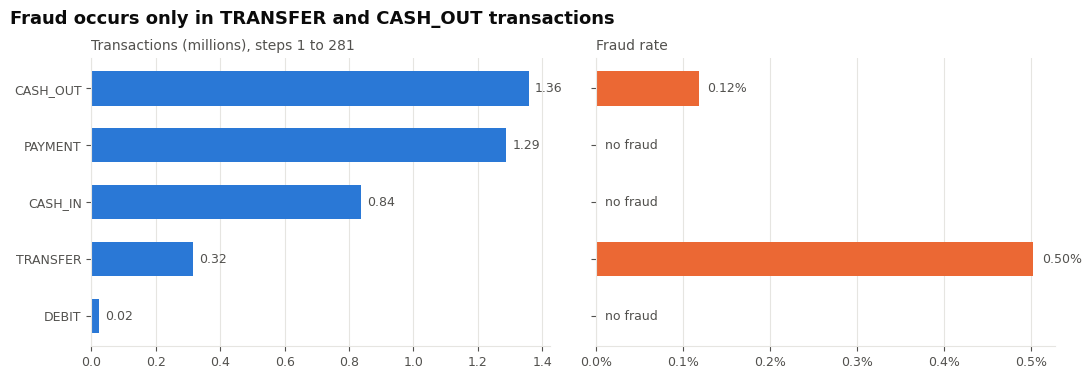

isFlaggedFraud, steps 1 to 281: 3 flags, 3 correct, recall 0.09%; full data: 16 flags


,transactions,frauds,fraud_rate
type,,,
DEBIT,23489,0,0.0000
TRANSFER,315549,1587,0.0050
CASH_IN,837044,0,0.0000
PAYMENT,1287159,0,0.0000
CASH_OUT,1357358,1606,0.0012


In [5]:
n_fraud = int(df.isFraud.sum())
print(f"Full data: {n_fraud:,} frauds of {len(df):,} transactions ({n_fraud / len(df):.3%}), "
      f"about {(len(df) - n_fraud) / n_fraud:,.0f} legitimate transactions per fraud; "
      f"fraud types: {sorted(df.loc[df.isFraud == 1, 'type'].astype(str).unique())}")

e = df.loc[early, ["type", "isFraud", "isFlaggedFraud"]]
by_type = (e.groupby("type", observed=True)
             .agg(transactions=("isFraud", "size"), frauds=("isFraud", "sum"), fraud_rate=("isFraud", "mean"))
             .sort_values("transactions"))
print(f"Steps 1 to {TRAIN_END}: {int(e.isFraud.sum()):,} frauds of {len(e):,} transactions ({e.isFraud.mean():.3%})")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
names = by_type.index.astype(str)
a1.barh(names, by_type.transactions / 1e6, color=LEGIT, height=0.6)
a1.set_title(f"Transactions (millions), steps 1 to {TRAIN_END}")
a1.grid(axis="y", visible=False)
for y, v in enumerate(by_type.transactions / 1e6):
    a1.text(v + 0.02, y, f"{v:.2f}", va="center", fontsize=9, color=INK2)

colors = [FRAUD if r > 0 else MUTED for r in by_type.fraud_rate]
a2.barh(names, by_type.fraud_rate * 100, color=colors, height=0.6)
a2.set_title("Fraud rate")
a2.xaxis.set_major_formatter(pct)
a2.grid(axis="y", visible=False)
for y, r in enumerate(by_type.fraud_rate):
    a2.text(r * 100 + 0.01, y, f"{r:.2%}" if r > 0 else "no fraud", va="center", fontsize=9, color=INK2)
fig.tight_layout(); headline(fig, "Fraud occurs only in TRANSFER and CASH_OUT transactions"); save(fig, "type_volume_fraud_rate"); plt.show()

flag = e.isFlaggedFraud == 1
print(f"isFlaggedFraud, steps 1 to {TRAIN_END}: {int(flag.sum())} flags, {int(e.loc[flag, 'isFraud'].sum())} correct, "
      f"recall {e.loc[flag, 'isFraud'].sum() / e.isFraud.sum():.2%}; full data: {int(df.isFlaggedFraud.sum())} flags")
del e
by_type

Over the full data, fraud represents 0.129% of transactions, roughly one fraud for every 774 legitimate payments; within steps 1 to 281 the rate is 0.084%. All frauds are TRANSFER or CASH_OUT operations, which matches the fraud scenario in the PaySim description: taking control of an account, transferring the funds and cashing them out. TRANSFER is less frequent than CASH_OUT but four times riskier (0.50% against 0.12%). The built-in `isFlaggedFraud` rule flags only 3 transactions in this period (16 in the full data), all of them fraud, so it can serve only as a naive baseline. Since the other three types contain no fraud, the following sections focus on TRANSFER and CASH_OUT (`tc`).

In [6]:
tc = df[early & df.type.isin(["TRANSFER", "CASH_OUT"])].copy()
tc["type"] = tc["type"].cat.remove_unused_categories()
print(f"TRANSFER and CASH_OUT, steps 1 to {TRAIN_END}: {len(tc):,} transactions, {int(tc.isFraud.sum()):,} frauds, "
      f"fraud rate {tc.isFraud.mean():.3%} (about {(tc.isFraud == 0).sum() / tc.isFraud.sum():,.0f} legitimate per fraud)")

TRANSFER and CASH_OUT, steps 1 to 281: 1,672,907 transactions, 3,193 frauds, fraud rate 0.191% (about 523 legitimate per fraud)


## Transaction amount

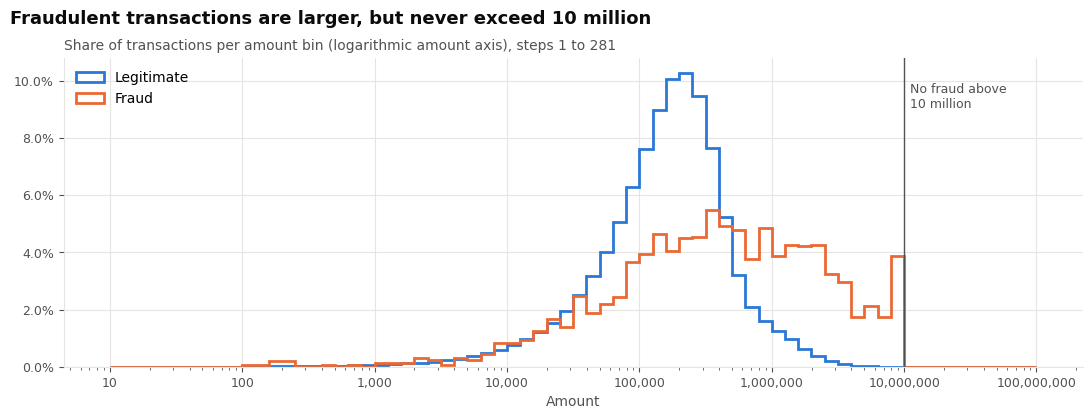

Frauds at exactly 10,000,000: 72; transactions above 10,000,000: 208, of which fraud: 0
Amount outliers (above Q3 + 1.5 IQR = 634,153): 7.22% of transactions, fraud rate 1.08% against 0.12% otherwise


,count,50%,mean,90%,max
isFraud,,,,,
legitimate,"1,669,714.0000","170,498.0200","261,357.5151","513,532.9310","92,445,516.6400"
fraud,"3,193.0000","412,511.3200","1,351,254.1253","3,832,058.3400","10,000,000.0000"


In [7]:
bins = np.logspace(1, 8, 71) * 1.0001   # 10 million falls just inside a bin edge
fig, ax = plt.subplots(figsize=(11, 4))
for label, color, name in [(0, LEGIT, "Legitimate"), (1, FRAUD, "Fraud")]:
    s = tc.loc[(tc.isFraud == label) & (tc.amount > 0), "amount"]
    ax.hist(s, bins=bins, weights=np.full(len(s), 100 / len(s)), histtype="step", lw=2, color=color, label=name)
ax.set_xscale("log")
ax.axvline(1e7, color=INK2, lw=1)
ax.text(1.1e7, ax.get_ylim()[1] * 0.92, "No fraud above\n10 million", fontsize=9, color=INK2, va="top")
ax.set_title(f"Share of transactions per amount bin (logarithmic amount axis), steps 1 to {TRAIN_END}")
ax.set_xlabel("Amount")
ax.yaxis.set_major_formatter(pct)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.legend(loc="upper left")
fig.tight_layout(); headline(fig, "Fraudulent transactions are larger, but never exceed 10 million"); save(fig, "amount_distribution"); plt.show()

summary = tc.groupby("isFraud").amount.describe(percentiles=[.5, .9]).rename(index={0: "legitimate", 1: "fraud"})
print(f"Frauds at exactly 10,000,000: {((tc.amount == 1e7) & (tc.isFraud == 1)).sum():,}; "
      f"transactions above 10,000,000: {(tc.amount > 1e7).sum():,}, of which fraud: {int(tc.loc[tc.amount > 1e7, 'isFraud'].sum())}")
q1, q3 = tc.amount.quantile([.25, .75])
outlier = tc.amount > q3 + 1.5 * (q3 - q1)
print(f"Amount outliers (above Q3 + 1.5 IQR = {q3 + 1.5 * (q3 - q1):,.0f}): {outlier.mean():.2%} of transactions, "
      f"fraud rate {tc.loc[outlier, 'isFraud'].mean():.2%} against {tc.loc[~outlier, 'isFraud'].mean():.2%} otherwise")
summary[["count", "50%", "mean", "90%", "max"]]

The median fraud (412,511) is about 2.4 times the median legitimate transfer or withdrawal (170,498). Fraudulent amounts are capped at exactly 10 million, with 72 frauds at the cap in this period, while 208 legitimate transactions exceed it. The cap is a property of the simulator; a tree-based model could learn that very large amounts are safe, which should be stated as a limitation. Amounts above the usual outlier bound (Q3 + 1.5 IQR, about 634,000) make up 7.2% of transactions and have a fraud rate of 1.08%, against 0.12% for the rest, so they should not be removed during cleaning.

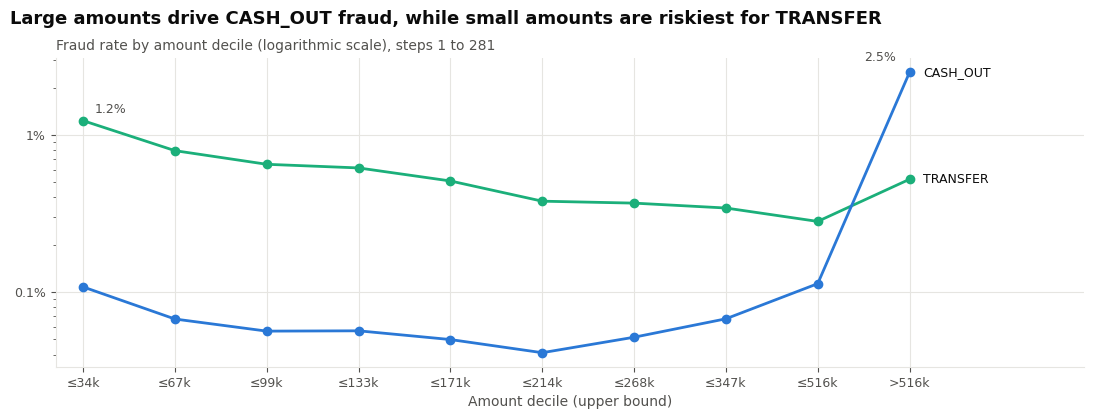

type,CASH_OUT,TRANSFER
amount_decile,,
"(-0.001, 34140.454]",0.1080,1.2310
"(34140.454, 66670.908]",0.0670,0.7930
"(66670.908, 99212.764]",0.0560,0.6500
"(99212.764, 133419.478]",0.0570,0.6160
"(133419.478, 170632.94]",0.0500,0.5090
"(170632.94, 213815.428]",0.0410,0.3780
"(213815.428, 268468.06]",0.0520,0.3680
"(268468.06, 347486.084]",0.0680,0.3420
"(347486.084, 515609.716]",0.1130,0.2810


In [8]:
tc["amount_decile"] = pd.qcut(tc.amount, 10)
dec = tc.groupby(["amount_decile", "type"], observed=True).isFraud.mean().unstack() * 100
upper = [iv.right for iv in dec.index]
labels = [f"≤{u/1e3:,.0f}k" for u in upper[:-1]] + [f">{upper[-2]/1e3:,.0f}k"]

fig, ax = plt.subplots(figsize=(11, 4))
x = np.arange(len(dec))
for col, color in [("TRANSFER", TRANSFER_C), ("CASH_OUT", CASH_OUT_C)]:
    ax.plot(x, dec[col], marker="o", ms=6, color=color)
    ax.text(x[-1] + 0.15, dec[col].iloc[-1], col, color=INK, fontsize=9, va="center")
ax.set_yscale("log")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:g}%"))
ax.set_xticks(x, labels)
ax.set_xlim(-0.3, len(x) - 0.1 + 1.0)
ax.set_title(f"Fraud rate by amount decile (logarithmic scale), steps 1 to {TRAIN_END}")
ax.set_xlabel("Amount decile (upper bound)")
ax.annotate(f"{dec['CASH_OUT'].iloc[-1]:.1f}%", (x[-1], dec["CASH_OUT"].iloc[-1]), textcoords="offset points",
            xytext=(-10, 8), ha="right", fontsize=9, color=INK2)
ax.annotate(f"{dec['TRANSFER'].iloc[0]:.1f}%", (x[0], dec["TRANSFER"].iloc[0]), textcoords="offset points",
            xytext=(8, 6), fontsize=9, color=INK2)
fig.tight_layout(); headline(fig, "Large amounts drive CASH_OUT fraud, while small amounts are riskiest for TRANSFER"); save(fig, "fraud_rate_by_amount_and_type"); plt.show()
dec.round(3)

Amount and type interact. For CASH_OUT, the fraud rate stays between 0.04% and 0.11% in the first nine deciles and rises to 2.5% in the top decile. For TRANSFER, the fraud rate is highest for the smallest amounts (1.2%) and declines as the amount grows, with a small rise in the top decile. A single global effect of amount would therefore be misleading; tree-based models capture this interaction directly, and a linear model would require an amount by type interaction term.

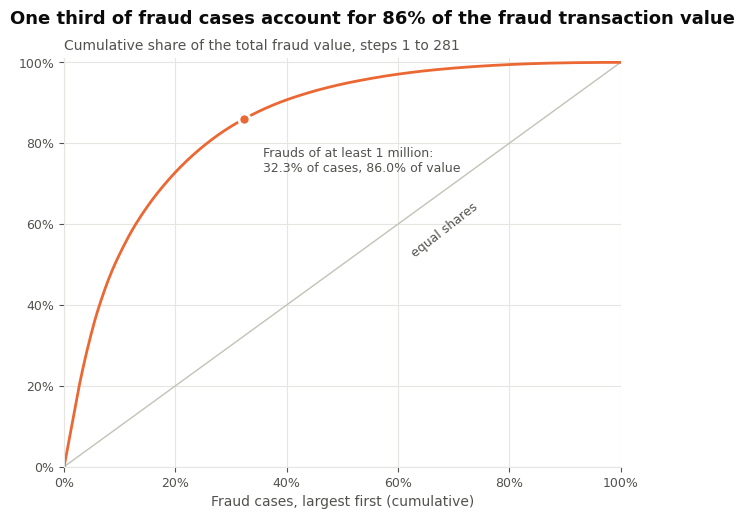

Total fraud value: 4,314,554,422; top 20% of cases: 72.8% of value


In [9]:
fa = np.sort(tc.loc[tc.isFraud == 1, "amount"].to_numpy())[::-1]
cum_cases = np.arange(1, len(fa) + 1) / len(fa) * 100
cum_value = np.cumsum(fa) / fa.sum() * 100
k = int((fa >= 1e6).sum())

fig, ax = plt.subplots(figsize=(6.5, 5))
ax.plot([0, 100], [0, 100], color=MUTED, lw=1)
ax.plot(cum_cases, cum_value, color=FRAUD)
ax.plot(cum_cases[k - 1], cum_value[k - 1], "o", ms=8, color=FRAUD, mec="white", mew=2)
ax.annotate(f"Frauds of at least 1 million:\n{cum_cases[k-1]:.1f}% of cases, {cum_value[k-1]:.1f}% of value",
            (cum_cases[k - 1], cum_value[k - 1]), textcoords="offset points", xytext=(14, -38), fontsize=9, color=INK2)
ax.text(62, 52, "equal shares", color=INK2, fontsize=9, rotation=38)
ax.set_xlim(0, 100); ax.set_ylim(0, 101)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0)); ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_xlabel("Fraud cases, largest first (cumulative)")
ax.set_title(f"Cumulative share of the total fraud value, steps 1 to {TRAIN_END}")
fig.tight_layout(); headline(fig, "One third of fraud cases account for 86% of the fraud transaction value"); save(fig, "fraud_value_concentration"); plt.show()
print(f"Total fraud value: {fa.sum():,.0f}; top 20% of cases: {cum_value[int(len(fa) * 0.2) - 1]:.1f}% of value")

Fraud transaction value is highly concentrated: frauds of at least 1 million make up 32.3% of the cases but 86.0% of the total fraud value of 4.31 billion in this period, and the largest 20% of cases account for 72.8%. The amount of a fraudulent transaction is not the same as the actual loss, which the data does not record. Under a cost matrix where a missed fraud costs its amount, the evaluation will be driven by these large cases. Recall should therefore be reported both by number of cases and by value caught.

## Hour of day

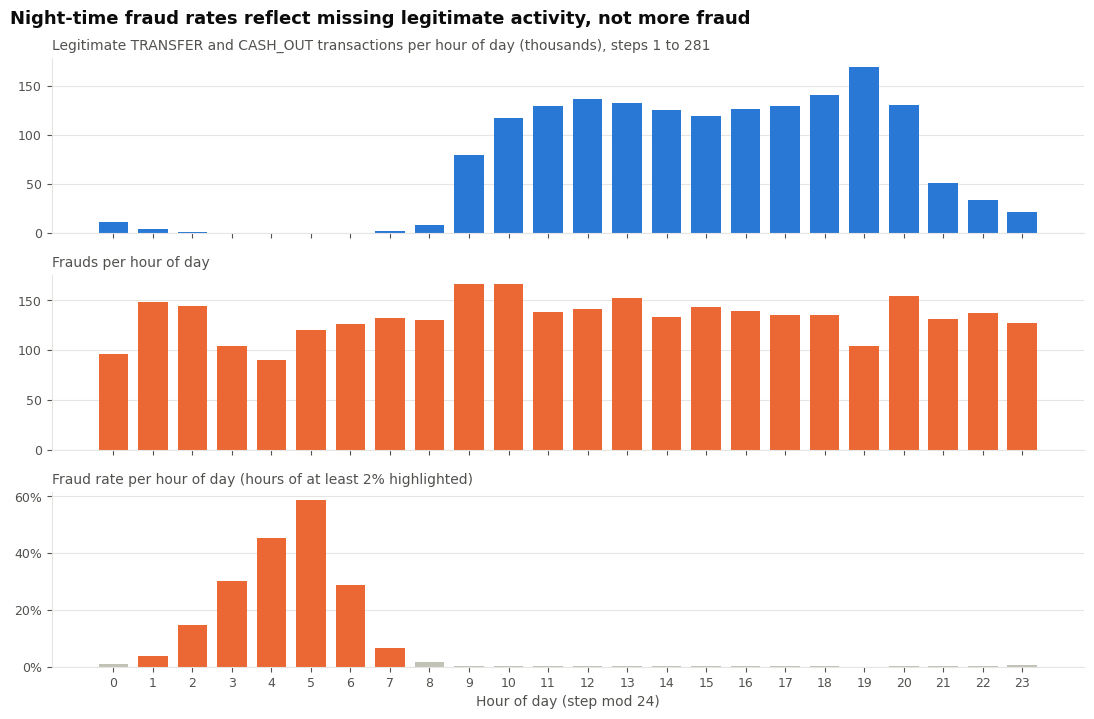

Frauds per hour: 90 to 167; legitimate per hour: 85 (hour 5) to 169,906 (hour 19)
Hours with a fraud rate of at least 2%: [1, 2, 3, 4, 5, 6, 7]
Fraud rate 03:00 to 06:00: 28.6% to 58.5%; 09:00 to 20:00: 0.06% to 0.21%


hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
legit,"10,822.0000","3,826.0000",841.0000,239.0000,109.0000,85.0000,314.0000,"1,895.0000","8,102.0000","79,220.0000",...,"125,622.0000","119,307.0000","126,524.0000","129,883.0000","140,588.0000","169,906.0000","130,261.0000","51,488.0000","33,282.0000","20,928.0000"
fraud,96.0000,148.0000,144.0000,104.0000,90.0000,120.0000,126.0000,132.0000,130.0000,167.0000,...,133.0000,143.0000,139.0000,135.0000,135.0000,104.0000,154.0000,131.0000,137.0000,127.0000
fraud_rate,0.8790,3.7240,14.6190,30.3210,45.2260,58.5370,28.6360,6.5120,1.5790,0.2100,...,0.1060,0.1200,0.1100,0.1040,0.0960,0.0610,0.1180,0.2540,0.4100,0.6030


In [10]:
hourly = tc.groupby("hour").agg(legit=("isFraud", lambda s: int((s == 0).sum())), fraud=("isFraud", "sum"))
hourly["fraud_rate"] = hourly.fraud / (hourly.legit + hourly.fraud) * 100
night = hourly.fraud_rate >= 2

fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
axes[0].bar(hourly.index, hourly.legit / 1e3, color=LEGIT, width=0.75)
axes[0].set_title(f"Legitimate TRANSFER and CASH_OUT transactions per hour of day (thousands), steps 1 to {TRAIN_END}")
axes[1].bar(hourly.index, hourly.fraud, color=FRAUD, width=0.75)
axes[1].set_title("Frauds per hour of day")
axes[2].bar(hourly.index, hourly.fraud_rate, color=[FRAUD if n else MUTED for n in night], width=0.75)
axes[2].yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
axes[2].set_title("Fraud rate per hour of day (hours of at least 2% highlighted)")
axes[2].set_xticks(range(24))
axes[2].set_xlabel("Hour of day (step mod 24)")
for ax in axes:
    ax.grid(axis="x", visible=False)
fig.tight_layout(); headline(fig, "Night-time fraud rates reflect missing legitimate activity, not more fraud"); save(fig, "volume_fraud_by_hour"); plt.show()
print(f"Frauds per hour: {hourly.fraud.min()} to {hourly.fraud.max()}; legitimate per hour: "
      f"{hourly.legit.min():,} (hour {hourly.legit.idxmin()}) to {hourly.legit.max():,} (hour {hourly.legit.idxmax()})")
print(f"Hours with a fraud rate of at least 2%: {list(hourly.index[night])}")
print(f"Fraud rate 03:00 to 06:00: {hourly.fraud_rate.loc[3:6].min():.1f}% to {hourly.fraud_rate.loc[3:6].max():.1f}%; "
      f"09:00 to 20:00: {hourly.fraud_rate.loc[9:20].min():.2f}% to {hourly.fraud_rate.loc[9:20].max():.2f}%")
hourly.round(3).T

The number of frauds is nearly constant across the day (90 to 167 per hour), whereas legitimate activity ranges from 85 transactions at 05:00 to 169,906 at 19:00. The resulting fraud rate is at least 2% between 01:00 and 07:00 and reaches 58.5% at 05:00, compared with 0.06% to 0.21% between 09:00 and 20:00. The window 01:00 to 07:00 is proposed for a night indicator. Hour of day is therefore a useful feature, encoded cyclically or as a night indicator, but the strength of the effect stems from the simulator and is likely weaker in real data.

## Balance columns: timing and reliability

The four balance columns differ in when they are recorded, so they are examined separately.

| Column | Recorded | Known when the transaction is scored |
|---|---|---|
| `oldbalanceOrg` | before the transaction | yes |
| `oldbalanceDest` | before the transaction | yes, if the recipient is a customer of the same provider; not recorded for merchants |
| `newbalanceOrig` | after the transaction | no |
| `newbalanceDest` | after the transaction | no |

The dataset description on Kaggle states: "Transactions which are detected as fraud are cancelled, so for fraud detection these columns (oldbalanceOrg, newbalanceOrig, oldbalanceDest, newbalanceDest) must not be used." It also describes the fraud agents as aiming to "empty the funds by transferring to another account and then cashing out of the system". The checks below test what these statements imply for each column.

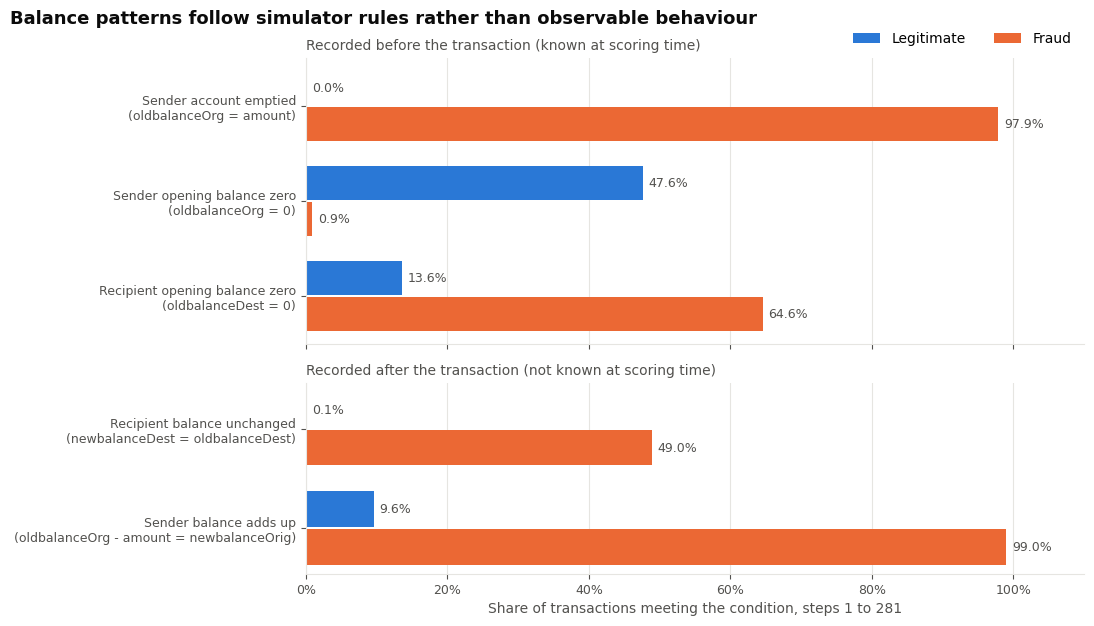

Recipient opening balance zero, first-time recipients: 58.1%; known recipients: 6.4%


Legitimate  \
Recorded before the transaction (known at scori... Sender account emptied\n(oldbalanceOrg = amount)        0.0000   
                                                   Sender opening balance zero\n(oldbalanceOrg = 0)       47.5900   
                                                   Recipient opening balance zero\n(oldbalanceDest...     13.5700   
Recorded after the transaction (not known at sc... Recipient balance unchanged\n(newbalanceDest = ...      0.0900   
                                                   Sender balance adds up\n(oldbalanceOrg - amount...      9.5600   

                                                                                                        Fraud  
Recorded before the transaction (known at scori... Sender account emptied\n(oldbalanceOrg = amount)   97.9000  
                                                   Sender opening balance zero\n(oldbalanceOrg = 0)    0.8800  
                                                   Recipient opening balance zero\n(oldbalanceDest... 64.6100  
Recorded after the transaction (not known at sc... Recipient balance unchanged\n(newbalanceDest = ... 48.9500  
                                                   Sender balance adds up\n(oldbalanceOrg - amount... 99.0000

In [11]:
groups = {
    "Recorded before the transaction (known at scoring time)": {
        "Sender account emptied\n(oldbalanceOrg = amount)": tc.oldbalanceOrg == tc.amount,
        "Sender opening balance zero\n(oldbalanceOrg = 0)": tc.oldbalanceOrg == 0,
        "Recipient opening balance zero\n(oldbalanceDest = 0)": tc.oldbalanceDest == 0,
    },
    "Recorded after the transaction (not known at scoring time)": {
        "Recipient balance unchanged\n(newbalanceDest = oldbalanceDest)": tc.newbalanceDest == tc.oldbalanceDest,
        "Sender balance adds up\n(oldbalanceOrg - amount = newbalanceOrig)": pd.Series(
            np.isclose(tc.oldbalanceOrg - tc.amount, tc.newbalanceOrig, rtol=0, atol=0.01), index=tc.index),
    },
}
tables = {g: pd.DataFrame({k: v.groupby(tc.isFraud).mean() * 100 for k, v in c.items()}).T.set_axis(["Legitimate", "Fraud"], axis=1)
          for g, c in groups.items()}

fig, axes = plt.subplots(2, 1, figsize=(11, 6.2), sharex=True, gridspec_kw={"height_ratios": [3, 2]})
for ax, (g, t) in zip(axes, tables.items()):
    y = np.arange(len(t))
    ax.barh(y - 0.19, t["Legitimate"], height=0.36, color=LEGIT, label="Legitimate")
    ax.barh(y + 0.19, t["Fraud"], height=0.36, color=FRAUD, label="Fraud")
    for i, (l, f) in enumerate(zip(t["Legitimate"], t["Fraud"])):
        ax.text(l + 0.8, i - 0.19, f"{l:.1f}%", va="center", fontsize=9, color=INK2)
        ax.text(f + 0.8, i + 0.19, f"{f:.1f}%", va="center", fontsize=9, color=INK2)
    ax.set_yticks(y, t.index)
    ax.invert_yaxis()
    ax.set_xlim(0, 110)
    ax.grid(axis="y", visible=False)
    ax.set_title(g)
axes[1].xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
axes[1].set_xlabel(f"Share of transactions meeting the condition, steps 1 to {TRAIN_END}")
axes[0].legend(loc="lower right", bbox_to_anchor=(1.0, 1.0), ncol=2)
fig.tight_layout(); headline(fig, "Balance patterns follow simulator rules rather than observable behaviour"); save(fig, "balance_patterns"); plt.show()
print(f"Recipient opening balance zero, first-time recipients: {(tc.loc[tc.is_new_dest == 1, 'oldbalanceDest'] == 0).mean():.1%}; "
      f"known recipients: {(tc.loc[tc.is_new_dest == 0, 'oldbalanceDest'] == 0).mean():.1%}")
pd.concat(tables).round(2)

**Post-transaction balances** (`newbalanceOrig`, `newbalanceDest`) describe the outcome of the transaction. A real-time scoring service evaluates a payment before it is completed, so these values do not exist at that moment, and using them would be a temporal leak. They also show a label-dependent recording effect: the recipient balance is unchanged after receiving the money in 49.0% of frauds, against 0.09% of legitimate transactions, which is consistent with the statement that fraudulent transactions are cancelled.

**Pre-transaction balances** (`oldbalanceOrg`, `oldbalanceDest`) are known at scoring time, so their exclusion rests on reliability rather than timing:

- 97.9% of frauds transfer exactly the sender balance, against 0.0% of legitimate transactions. This follows from the simulated fraud agent always emptying the account. Real fraud is not this regular, so a model relying on this rule (AUC 0.990 on its own) would mostly learn the simulator.
- Legitimate balances are often implausible: 47.6% of legitimate transactions start from a sender balance of zero although money is sent, and the sender balance adds up (opening balance minus amount equals closing balance) in only 9.6% of legitimate transactions, against 99.0% of frauds. The balances are thus recorded differently depending on the label.
- The recipient opening balance is zero for 64.6% of frauds and 13.6% of legitimate transactions. Part of this reflects first-time recipients (58.1% of them have a zero opening balance, against 6.4% of known recipients), which the recipient history features capture without relying on balances.

A high AUC is not by itself evidence of leakage. The exclusion of all four columns from the main model rests on the timing of the post-transaction values, on the label-dependent recording of all balances and on the explicit warning in the dataset description. A comparison model with the pre-transaction sender balance (for example `amount / oldbalanceOrg`) may be reported to show how much of the performance would depend on this artefact.

## Recipient history

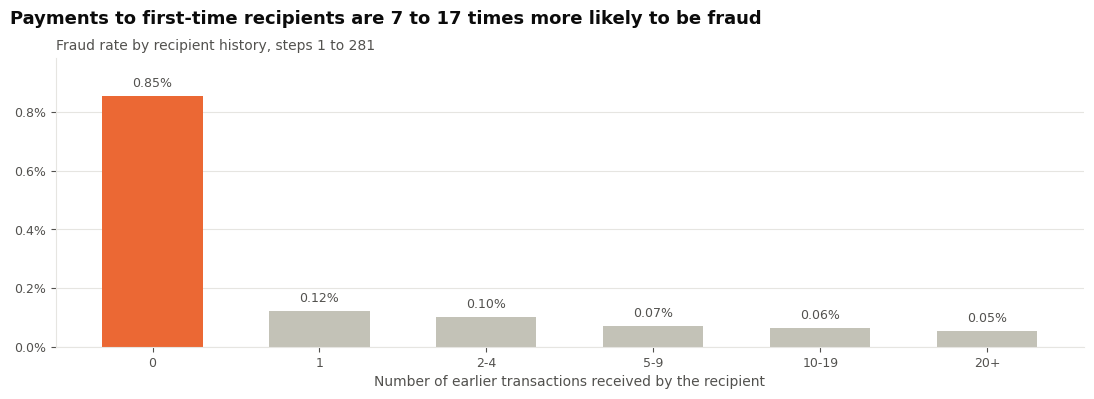

,transactions,frauds,fraud_rate,share_of_frauds,share_of_legitimate
dest_prior_count,,,,,
0,234549,2005,0.0085,0.6279,0.1393
1,182118,224,0.0012,0.0702,0.1089
2-4,389580,398,0.0010,0.1246,0.2331
5-9,380208,272,0.0007,0.0852,0.2275
10-19,331612,211,0.0006,0.0661,0.1985
20+,154840,83,0.0005,0.0260,0.0927


In [12]:
buckets = pd.cut(tc.dest_prior_count, [-1, 0, 1, 4, 9, 19, np.inf], labels=["0", "1", "2-4", "5-9", "10-19", "20+"])
rec = tc.groupby(buckets, observed=True).agg(transactions=("isFraud", "size"), frauds=("isFraud", "sum"),
                                             fraud_rate=("isFraud", "mean"))
rec["share_of_frauds"] = rec.frauds / rec.frauds.sum()
rec["share_of_legitimate"] = (rec.transactions - rec.frauds) / (rec.transactions - rec.frauds).sum()

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.bar(rec.index.astype(str), rec.fraud_rate * 100, color=[FRAUD] + [MUTED] * (len(rec) - 1), width=0.6)
for i, r in enumerate(rec.fraud_rate):
    ax.text(i, r * 100 + 0.03, f"{r:.2%}", ha="center", fontsize=9, color=INK2)
ax.yaxis.set_major_formatter(pct)
ax.set_ylim(0, rec.fraud_rate.max() * 100 * 1.15)
ax.grid(axis="x", visible=False)
ax.set_xlabel("Number of earlier transactions received by the recipient")
ax.set_title(f"Fraud rate by recipient history, steps 1 to {TRAIN_END}")
fig.tight_layout(); headline(fig, "Payments to first-time recipients are 7 to 17 times more likely to be fraud"); save(fig, "fraud_rate_by_recipient_history"); plt.show()
rec

A first-time recipient is involved in 62.8% of frauds but only 13.9% of legitimate transactions. The fraud rate is 0.85% when the recipient has never received money before, compared with 0.05% to 0.12% for recipients with a history. A first-time recipient is a `nameDest` that has not appeared earlier in the observed data; this does not show that the account was newly created, so a link to mule accounts remains a hypothesis. Because the feature uses earlier transactions only, it is available at scoring time.

## Discriminative power and redundancy of candidate features

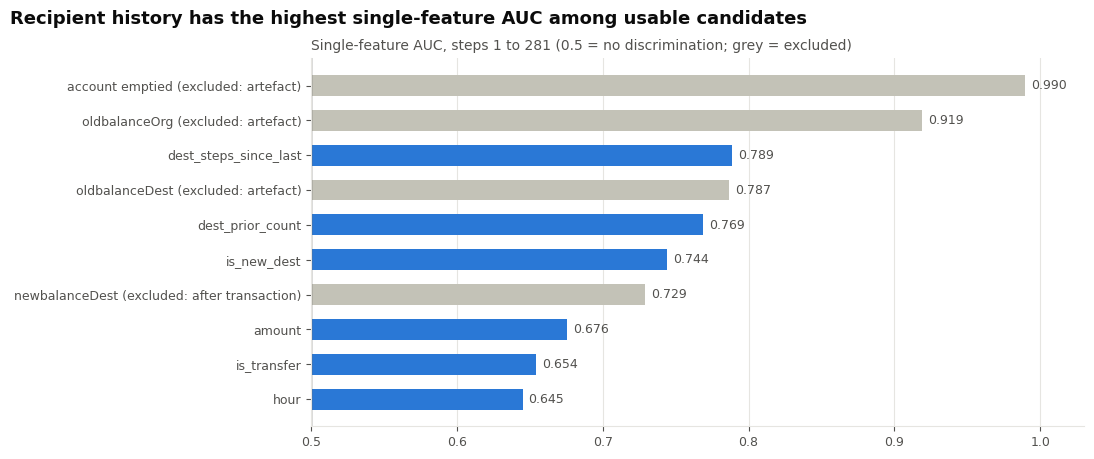

account emptied (excluded: artefact)           0.9900
oldbalanceOrg (excluded: artefact)             0.9190
dest_steps_since_last                          0.7890
oldbalanceDest (excluded: artefact)            0.7870
dest_prior_count                               0.7690
is_new_dest                                    0.7440
newbalanceDest (excluded: after transaction)   0.7290
amount                                         0.6760
is_transfer                                    0.6540
hour                                           0.6450
dtype: float64

In [13]:
tc["is_transfer"] = (tc.type == "TRANSFER").astype("int8")
tc["dest_steps_since_last_filled"] = tc.dest_steps_since_last.fillna(9999)
candidates = {
    "dest_steps_since_last": tc.dest_steps_since_last_filled,
    "dest_prior_count": tc.dest_prior_count,
    "is_new_dest": tc.is_new_dest,
    "amount": tc.amount,
    "hour": tc.hour,
    "is_transfer": tc.is_transfer,
    "oldbalanceOrg (excluded: artefact)": tc.oldbalanceOrg,
    "oldbalanceDest (excluded: artefact)": tc.oldbalanceDest,
    "newbalanceDest (excluded: after transaction)": tc.newbalanceDest,
    "account emptied (excluded: artefact)": (tc.oldbalanceOrg == tc.amount).astype("int8"),
}
auc = pd.Series({name: max(a, 1 - a) for name, a in
                 ((n, roc_auc_score(tc.isFraud, s)) for n, s in candidates.items())}).sort_values()

fig, ax = plt.subplots(figsize=(11, 4.4))
colors = [MUTED if "excluded" in n else LEGIT for n in auc.index]
ax.barh(auc.index, auc - 0.5, left=0.5, color=colors, height=0.6)
for i, v in enumerate(auc):
    ax.text(v + 0.004, i, f"{v:.3f}", va="center", fontsize=9, color=INK2)
ax.set_xlim(0.5, 1.03)
ax.axvline(0.5, color=INK2, lw=1)
ax.grid(axis="y", visible=False)
ax.set_title(f"Single-feature AUC, steps 1 to {TRAIN_END} (0.5 = no discrimination; grey = excluded)")
fig.tight_layout(); headline(fig, "Recipient history has the highest single-feature AUC among usable candidates"); save(fig, "feature_auc"); plt.show()
auc.sort_values(ascending=False).round(3)

Among the usable candidates examined, the recipient-based features have the highest single-feature AUC (0.74 to 0.79), followed by amount, type and hour (0.65 to 0.68). The excluded balance features reach up to 0.990 and are shown for reference only, with the reason for exclusion in brackets. These single-feature AUCs are a screening tool, not a measure of model performance; the model will rely on combining features, including the synthetic fields, and its performance is assessed on the validation set.

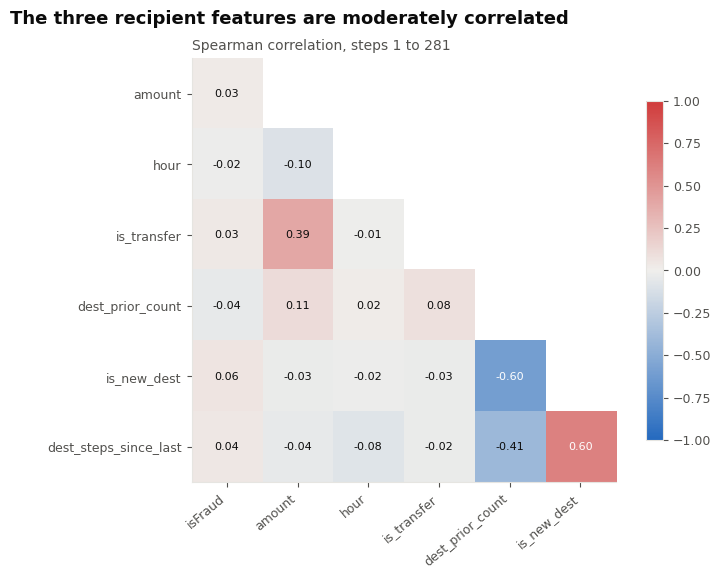

,isFraud,amount,hour,is_transfer,dest_prior_count,is_new_dest,dest_steps_since_last
isFraud,1.0000,0.0300,-0.0200,0.0300,-0.0400,0.0600,0.0400
amount,0.0300,1.0000,-0.1000,0.3900,0.1100,-0.0300,-0.0400
hour,-0.0200,-0.1000,1.0000,-0.0100,0.0200,-0.0200,-0.0800
is_transfer,0.0300,0.3900,-0.0100,1.0000,0.0800,-0.0300,-0.0200
dest_prior_count,-0.0400,0.1100,0.0200,0.0800,1.0000,-0.6000,-0.4100
is_new_dest,0.0600,-0.0300,-0.0200,-0.0300,-0.6000,1.0000,0.6000
dest_steps_since_last,0.0400,-0.0400,-0.0800,-0.0200,-0.4100,0.6000,1.0000


In [14]:
corr_cols = ["isFraud", "amount", "hour", "is_transfer", "dest_prior_count", "is_new_dest", "dest_steps_since_last_filled"]
corr = tc[corr_cols].corr(method="spearman").rename(index={"dest_steps_since_last_filled": "dest_steps_since_last"},
                                                 columns={"dest_steps_since_last_filled": "dest_steps_since_last"})
from matplotlib.colors import LinearSegmentedColormap
diverging = LinearSegmentedColormap.from_list("blue_grey_red", ["#256abf", "#f0efec", "#d03b3b"])

lower = corr.where(np.tril(np.ones(corr.shape, dtype=bool), k=-1)).iloc[1:, :-1]
diverging.set_bad("white")
fig, ax = plt.subplots(figsize=(7.5, 5.6))
im = ax.imshow(lower, cmap=diverging, vmin=-1, vmax=1)
ax.set_xticks(range(lower.shape[1]), lower.columns, rotation=40, ha="right")
ax.set_yticks(range(lower.shape[0]), lower.index)
ax.grid(False)
for i in range(lower.shape[0]):
    for j in range(lower.shape[1]):
        v = lower.iloc[i, j]
        if pd.notna(v):
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8, color="white" if abs(v) > 0.55 else INK)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title(f"Spearman correlation, steps 1 to {TRAIN_END}")
fig.tight_layout(); headline(fig, "The three recipient features are moderately correlated"); save(fig, "feature_correlation"); plt.show()
corr.round(2)

The three recipient features are correlated with each other (absolute Spearman correlation between 0.41 and 0.60), since `is_new_dest` is the zero case of `dest_prior_count` and the missing case of `dest_steps_since_last`. Amount and type are also related (0.39), as transfers tend to be larger. Correlation alone does not show that some of them are redundant for the model; whether one or two are enough should be tested on the validation set, for example by comparing models with and without each of them. Correlations with `isFraud` are small in absolute terms because of the class imbalance; the AUC above is a better measure of separation.

## Change over time and proposed split points (full data)

Choosing split points requires the whole timeline, so this section uses all steps and all transaction types. It does not relate features to the label, but it does use the labels of all periods: fraud counts and fraud rates over time, and the cumulative fraud count that defines option B. Option A places cut points at 60%, 75% and 90% of the cumulative number of transactions; option B uses the cumulative number of frauds instead.

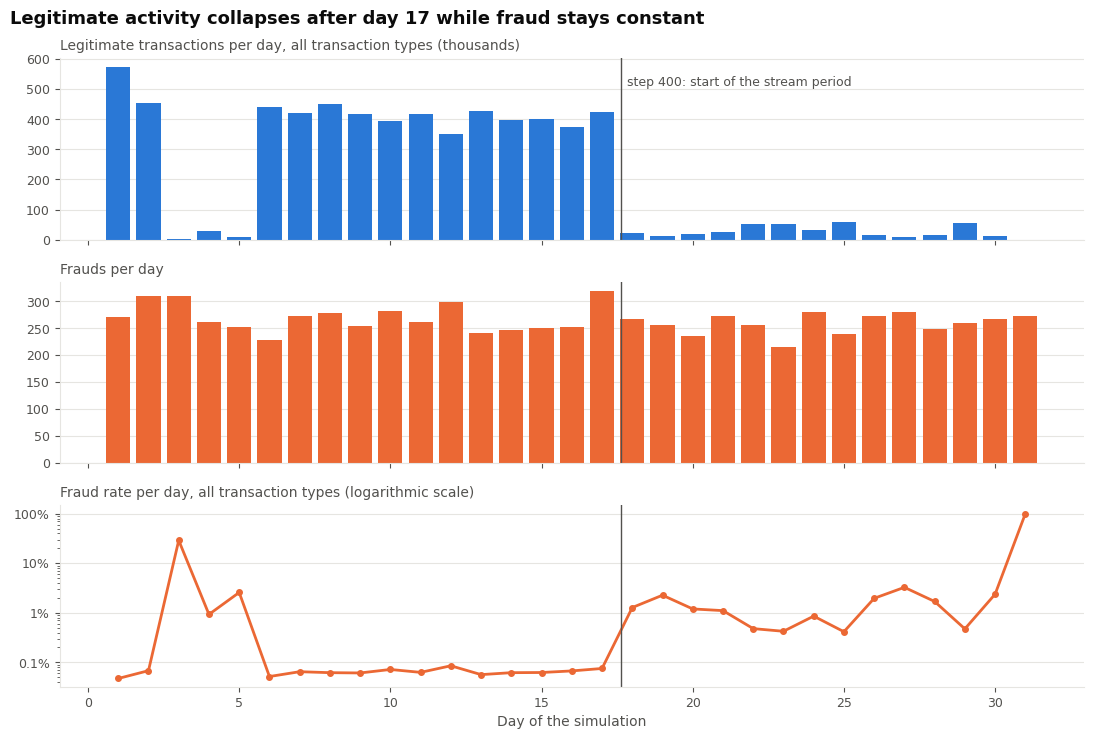

From step 400: 9.5% of transactions, 45.7% of frauds; fraud rate 0.078% before and 0.619% after
Frauds per day: 216 to 320; days without legitimate transactions: [31]


In [15]:
daily = df.groupby("day").agg(legit=("isFraud", lambda s: int((s == 0).sum())), fraud=("isFraud", "sum"))
daily["fraud_rate"] = daily.fraud / (daily.legit + daily.fraud) * 100
split_day = (400 - 1) / 24 + 1   # position of step 400 on the day axis

fig, axes = plt.subplots(3, 1, figsize=(11, 7.2), sharex=True)
axes[0].bar(daily.index, daily.legit / 1e3, color=LEGIT, width=0.8)
axes[0].set_title("Legitimate transactions per day, all transaction types (thousands)")
axes[1].bar(daily.index, daily.fraud, color=FRAUD, width=0.8)
axes[1].set_title("Frauds per day")
axes[2].plot(daily.index, daily.fraud_rate, color=FRAUD, marker="o", ms=4)
axes[2].set_yscale("log")
axes[2].yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:g}%"))
axes[2].set_title("Fraud rate per day, all transaction types (logarithmic scale)")
axes[2].set_xlabel("Day of the simulation")
for ax in axes:
    ax.axvline(split_day, color=INK2, lw=1)
    ax.grid(axis="x", visible=False)
axes[0].text(split_day + 0.2, axes[0].get_ylim()[1] * 0.85, "step 400: start of the stream period", fontsize=9, color=INK2)
fig.tight_layout(); headline(fig, "Legitimate activity collapses after day 17 while fraud stays constant"); save(fig, "volume_fraud_by_day"); plt.show()

late = df.step >= 400
print(f"From step 400: {late.mean():.1%} of transactions, {df.loc[late, 'isFraud'].sum() / n_fraud:.1%} of frauds; "
      f"fraud rate {df.loc[~late, 'isFraud'].mean():.3%} before and {df.loc[late, 'isFraud'].mean():.3%} after")
print(f"Frauds per day: {daily.fraud.min()} to {daily.fraud.max()}; days without legitimate transactions: {list(daily.index[daily.legit == 0])}")

Frauds are generated at a steady pace of 216 to 320 per day over the 31 days, whereas legitimate activity is concentrated in days 1 to 17, with much lower volumes on days 3 to 5 and no legitimate transaction at all on day 31. From step 400 onwards, the data contains 9.5% of all transactions but 45.7% of all frauds, and the fraud rate rises from 0.078% to 0.619%. This shift is a property of the simulation, not a change in fraud behaviour. It is also the reason the label analyses above are restricted to the earliest period: statistics on the full data would be dominated by the late period, which holds almost half of the frauds.

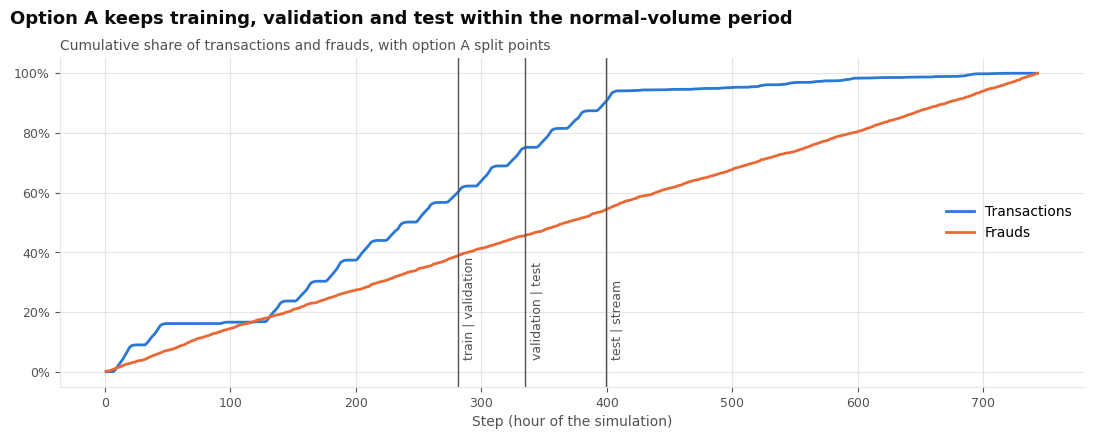

Option A (cumulative transactions), all types:


,first_step,last_step,transactions,frauds,fraud_rate,share_of_transactions,share_of_frauds
step,,,,,,,
train,1,281,3820599,3193,0.0008,0.6005,0.3888
validation,282,335,961244,556,0.0006,0.1511,0.0677
test,336,399,974277,712,0.0007,0.1531,0.0867
stream,400,743,606500,3752,0.0062,0.0953,0.4568


Option B (cumulative frauds), all types:


,first_step,last_step,transactions,frauds,fraud_rate,share_of_transactions,share_of_frauds
step,,,,,,,
train,1,439,6009593,4931,0.0008,0.9445,0.6004
validation,440,558,159102,1234,0.0078,0.0250,0.1502
test,559,671,127323,1240,0.0097,0.0200,0.1510
stream,672,743,66602,808,0.0121,0.0105,0.0984


Option A, TRANSFER and CASH_OUT only:


,first_step,last_step,transactions,frauds,fraud_rate,share_of_transactions,share_of_frauds,fraud_value
step,,,,,,,,
train,1,281,1672907,3193,0.0019,0.6038,0.3888,"4,314,554,422.2200"
validation,282,335,417316,556,0.0013,0.1506,0.0677,"758,612,396.7200"
test,336,399,424920,712,0.0017,0.1534,0.0867,"1,185,854,841.4900"
stream,400,743,255266,3752,0.0147,0.0921,0.4568,"5,797,393,767.4100"


In [16]:
by_step = df.groupby("step").agg(n=("isFraud", "size"), n_fraud=("isFraud", "sum"))
cum = by_step.cumsum() / by_step.sum()

def cuts(col):
    return [int(cum.index[np.searchsorted(cum[col].to_numpy(), s)]) for s in (.60, .75, .90)]

def split_table(cut_points, data=df):
    labels = pd.cut(data.step, [0, *cut_points, df.step.max()], labels=["train", "validation", "test", "stream"])
    t = data.groupby(labels, observed=True).agg(first_step=("step", "min"), last_step=("step", "max"),
                                                transactions=("isFraud", "size"), frauds=("isFraud", "sum"),
                                                fraud_rate=("isFraud", "mean"))
    t["share_of_transactions"] = t.transactions / len(data)
    t["share_of_frauds"] = t.frauds / t.frauds.sum()
    return t

a_cuts, b_cuts = cuts("n"), cuts("n_fraud")

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(cum.index, cum.n * 100, color=LEGIT, label="Transactions")
ax.plot(cum.index, cum.n_fraud * 100, color=FRAUD, label="Frauds")
for c, name in zip(a_cuts, ["train | validation", "validation | test", "test | stream"]):
    ax.axvline(c, color=INK2, lw=1)
    ax.text(c + 4, 4, name, rotation=90, fontsize=9, color=INK2, va="bottom")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_xlabel("Step (hour of the simulation)")
ax.set_title("Cumulative share of transactions and frauds, with option A split points")
ax.legend(loc="center right")
fig.tight_layout(); headline(fig, "Option A keeps training, validation and test within the normal-volume period"); save(fig, "split_cumulative_share"); plt.show()

print("Option A (cumulative transactions), all types:"); display(split_table(a_cuts))
print("Option B (cumulative frauds), all types:"); display(split_table(b_cuts))

tc_all = df.loc[df.type.isin(["TRANSFER", "CASH_OUT"]), ["step", "amount", "isFraud"]]
tc_split = split_table(a_cuts, tc_all)
tc_split["fraud_value"] = tc_all.loc[tc_all.isFraud == 1].groupby(
    pd.cut(tc_all.step, [0, *a_cuts, df.step.max()], labels=["train", "validation", "test", "stream"]), observed=True).amount.sum()
print("Option A, TRANSFER and CASH_OUT only:"); display(tc_split)

The two options differ mainly in where the shift at step 400 falls.

- **Option A** places training (steps 1 to 281), validation (282 to 335) and test (336 to 399) before the shift, with 556 and 712 frauds among the TRANSFER and CASH_OUT transactions of validation and test. The whole post-shift period (steps 400 to 743, 45.7% of the frauds) becomes the stream.
- **Option B** balances the number of frauds across sets. Its training set (steps 1 to 439) spans the shift, while validation (440 to 558) and test (559 to 671) lie entirely after it, with only 2.5% and 2.0% of the transactions and a fraud rate about ten times that of training. The stream is reduced to the last 72 steps (808 frauds), which include day 31 without any legitimate transaction.

A difference in distribution between training and test is not in itself a weakness: a deployed model has to predict a future that may differ from the past, and option B tests exactly that. The choice depends on what each set should measure. Option A is proposed because it separates the two questions. The test set measures performance in the period before the shift, under conditions similar to training, and the stream measures performance after the shift, which is also where the monitoring component has to detect the change. Under option A both results must be reported; the test result alone would describe only the period before the shift. Precision on the stream is expected to differ markedly from validation because of the higher fraud rate. The final choice is made with the modelling and evaluation members before modelling starts.

## Next steps

- Generate a `customer_id`, since `nameOrig` is almost always unique, and derive time of day from `step % 24`.
- Keep the fraud and legitimate distributions of the synthetic fields overlapping.
- Decide on the 16 zero-amount frauds; keep amount outliers and the 10 million cap, documented as a simulation limit.
- Use `log1p(amount)`, cyclical hour, `is_transfer` and recipient history computed from earlier transactions. Exclude the balance columns, `nameOrig` and `isFlaggedFraud`; use `step` only to split the data and derive features.
- Handle about 523 legitimate transactions per fraud within TRANSFER and CASH_OUT, and report recall by count and by value.
- Fix one split option before modelling; under option A, report results on both the test set and the stream.